<a href="https://colab.research.google.com/github/harimshin/data-science-portfolio/blob/main/Bionsight_Basics_of_Proteomics.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### **Bionsight | Data Scientist Take-Home Assignment | Basics of Proteomics**
**작성자 이름: 신하림**
* 목표: 동일한 FASTA 데이터를 두 분석 도구(TOOL-A, TOOL-B)로 분석하고, Reference Protein Sequence를 기준으로 Unique Peptide 및 Protein 식별 수, Simplified-Semi-Tryptic 비율, Protein Sequence Coverage를 비교하여 더 우수한 분석 도구를 선정한다.

**1. 데이터 불러오기**
* FASTA 파일은 단백질 서열 정보를 포함하는 txt 형식이므로 open()을 사용해서 각 라인을 불러온다.
* TOOL_A result와 TOOL_B result은 tsv 형식이므로 separator을 tab으로 지정하고 pd.read_csv 함수를 통하여 불러온다.

In [1]:
import requests

fasta_url = 'https://raw.githubusercontent.com/harimshin/private_data/refs/heads/main/uniprot_sprot_2021-01-04_HUMAN.txt'

response = requests.get(fasta_url)
response.raise_for_status()
fasta_lines = response.text.splitlines()

In [2]:
import pandas as pd

tool_a_url = 'https://raw.githubusercontent.com/harimshin/private_data/refs/heads/main/tool_A_results.tsv'
tool_b_url = 'https://raw.githubusercontent.com/harimshin/private_data/refs/heads/main/tool_B_results.tsv'

tool_a_df = pd.read_csv(tool_a_url, sep='\t')
tool_b_df = pd.read_csv(tool_b_url, sep='\t')

**2. 데이터 전처리**

* FASTA file의 각 라인에서 Protein 이름, Sequence, Sequence 길이를 추출한다. (preprocess_fasta)
* TOOL-A result에서 하나의 row에 여러 Protein이 매핑된 경우 각각 별도 row로 분리한다. (preprocess_tool_a)
* TOOL-B result의 동일한 Protein-Peptide 조합의 중복을 제거한다. (preprocess_tool_b)

In [3]:
def preprocess_fasta(fasta_lines):

    proteins = []
    current_name = None
    current_sequence = []

    # Iterate through FASTA lines
    for line in fasta_lines:

        line = line.strip()

        # Skip empty lines
        if not line:
            continue

        # Identify a new protein entry
        if line.startswith(">"):

            # Save the previous protein entry
            if current_name is not None:
                proteins.append({
                    "Protein_Name": current_name,
                    "Sequence": "".join(current_sequence)
                })

            # Extract protein name from FASTA header
            metadata = line[1:].split()
            current_name = metadata[0].split("|")[2]

            # Reset sequence
            current_sequence = []

        else:
            # Collect sequence lines
            current_sequence.append(line)

    # Save the last protein entry
    if current_name is not None:
        proteins.append({
            "Protein_Name": current_name,
            "Sequence": "".join(current_sequence)
        })

    # Create DataFrame
    cleaned_df = pd.DataFrame(proteins)

    # Calculate sequence length
    cleaned_df["Sequence_Length"] = cleaned_df["Sequence"].str.len()

    return cleaned_df

In [4]:
fasta_clean = preprocess_fasta(fasta_lines)
print(fasta_clean.head(5))

  Protein_Name                                           Sequence  \
0  1433B_HUMAN  MTMDKSELVQKAKLAEQAERYDDMAAAMKAVTEQGHELSNEERNLL...   
1  1433E_HUMAN  MDDREDLVYQAKLAEQAERYDEMVESMKKVAGMDVELTVEERNLLS...   
2  1433F_HUMAN  MGDREQLLQRARLAEQAERYDDMASAMKAVTELNEPLSNEDRNLLS...   
3  1433G_HUMAN  MVDREQLVQKARLAEQAERYDDMAAAMKNVTELNEPLSNEERNLLS...   
4  1433S_HUMAN  MERASLIQKAKLAEQAERYEDMAAFMKGAVEKGEELSCEERNLLSV...   

   Sequence_Length  
0              246  
1              255  
2              246  
3              247  
4              248  


In [5]:
def preprocess_tool_a(df):

    # Split multiple protein names into separate rows
    df = df.copy()
    df["ProteinName"] = df["ProteinName"].fillna("").astype(str)
    df["StrippedSequence"] = df["StrippedSequence"].fillna("").astype(str)

    df["ProteinName"] = df["ProteinName"].str.split(";")
    df = df.explode("ProteinName")

    # Clean protein names and peptide sequences
    df["ProteinName"] = df["ProteinName"].str.strip()
    df["Sequence"] = df["StrippedSequence"].str.strip().str.upper()

    # Remove empty values and duplicates
    df = df[
        (df["ProteinName"] != "") &
        (df["Sequence"] != "")
    ]

    df = df[["ProteinName", "Sequence"]].drop_duplicates()

    return df.reset_index(drop=True)

In [6]:
def preprocess_tool_b(df):

    df = df.copy()

    # Extract protein identifier from metadata
    df["ProteinName"] = (
        df["ProteinName"]
        .fillna("")
        .astype(str)
        .str.split("|", regex=False)
        .str[2]
        .str.split()
        .str[0]
    )

    # Clean peptide sequences
    df["Sequence"] = (
        df["Sequence"]
        .fillna("")
        .astype(str)
        .str.strip()
        .str.upper()
    )

    # Remove empty values and duplicates
    df = df[
        (df["ProteinName"] != "") &
        (df["Sequence"] != "")
    ]

    df = df[["ProteinName", "Sequence"]].drop_duplicates()

    return df.reset_index(drop=True)

In [7]:
# Apply preprocessing
tool_a_clean = preprocess_tool_a(tool_a_df)
tool_b_clean = preprocess_tool_b(tool_b_df)

print("TOOL-A:", len(tool_a_clean))
print("TOOL-B:", len(tool_b_clean))

TOOL-A: 53492
TOOL-B: 16395


In [8]:
print(tool_a_clean.head(5))

   ProteinName            Sequence
0   SRC8_HUMAN            PVEAVTSK
1    APT_HUMAN  LQAEVLECVSLVELTSLK
2  TRXR1_HUMAN     VVYENAYGQFIGPHR
3  GALD1_HUMAN       AMEFVDVTESNAR
4  TRADD_HUMAN       VVLSDAYAHPQQK


In [9]:
print(tool_a_clean.head())

   ProteinName            Sequence
0   SRC8_HUMAN            PVEAVTSK
1    APT_HUMAN  LQAEVLECVSLVELTSLK
2  TRXR1_HUMAN     VVYENAYGQFIGPHR
3  GALD1_HUMAN       AMEFVDVTESNAR
4  TRADD_HUMAN       VVLSDAYAHPQQK


**3. Peptide의 Simplified-Semi-Tryptic 판별**

* Simplified-Semi-Tryptic 판별 조건
  * 핵심 조건: Peptide 마지막 아미노산과 직전 Protein 아미노산 중 정확히 하나가 K 또는 R인 경우 Simplified-Semi-Tryptic으로 분류한다.
  * 추가 조건 1: Peptide Sequence가 Protein의 Sequence에서 여러 번 나타날 경우 첫 번째 나타나는 경우로 한다.
  * 추가 조건 2: Peptide Sequence가 Protein 의 Sequence에 처음 시작일 경우 (직전 아미노산이 없을 경우) K나 R로 끝난 것으로 간주한다.
  * 추가 조건 3: Protein 이름 정보가 없을 때는 Simplified-Semi-Tryptic가 아니다.

* FASTA file의 Protein 이름을 key로 Sequence를 value로 하는 dictionary를 생성하고 이후 Reference Protein Sequence를 찾는데 사용한다. (build_protein_dict)
* Peptide 마지막 아미노산과 직전 Protein 아미노산 중 정확히 하나가 K 또는 R인 경우 Simplified-Semi-Tryptic으로 분류한다. [핵심 조건 + 추가 조건 2] (is_simplified_semi_tryptic)
* Peptide의 Simplified-Semi-Tryptic을 판별한다. [추가 조건 1 + 추가 조건 3] (analyze_peptides)




In [10]:
def build_protein_dict(fasta_df):

    # Create a dictionary of protein sequences
    return dict(zip(
        fasta_df["Protein_Name"].str.strip(),
        fasta_df["Sequence"].str.strip().str.upper()
    ))

In [11]:
def find_first_occurrence(protein_seq, peptide_seq):

    # Find the first occurrence of the peptide
    position = protein_seq.find(peptide_seq)

    return position

In [12]:
def is_simplified_semi_tryptic(protein_seq, peptide_seq, position):

    # Check whether the peptide ends with K or R
    peptide_ends_kr = peptide_seq[-1] in ["K", "R"]

    # Check the amino acid immediately before the peptide
    if position == 0:
        previous_ends_kr = True
    else:
        previous_ends_kr = protein_seq[position - 1] in ["K", "R"]

    # Apply the simplified semi-tryptic criteria
    return peptide_ends_kr != previous_ends_kr

In [13]:
def analyze_peptides(tool_df, protein_dict):

    results = []

    # Match each peptide against its reference protein
    for _, row in tool_df.iterrows():

        protein_name = row["ProteinName"]
        peptide = row["Sequence"]

        # Skip rows without valid protein information
        if pd.isna(protein_name) or protein_name not in protein_dict:
            continue

        protein_seq = protein_dict[protein_name]

        # Find the first occurrence of the peptide
        position = protein_seq.find(peptide)

        if position == -1:
            continue

        # Classify the peptide as simplified semi-tryptic
        semi_flag = is_simplified_semi_tryptic(
            protein_seq, peptide, position
        )

        results.append({
            "ProteinName": protein_name,
            "Sequence": peptide,
            "Position": position,
            "Semi_Tryptic": semi_flag
        })

    return pd.DataFrame(results)

In [14]:
# Build reference dictionary
protein_dict = build_protein_dict(fasta_clean)

# Map peptides
tool_a_analyzed = analyze_peptides(tool_a_clean, protein_dict)
tool_b_analyzed = analyze_peptides(tool_b_clean, protein_dict)

print("TOOL-A mapped pairs:", len(tool_a_analyzed))
print("TOOL-B mapped pairs:", len(tool_b_analyzed))

TOOL-A mapped pairs: 53392
TOOL-B mapped pairs: 16257


In [15]:
print(tool_a_analyzed.head(5))

   ProteinName            Sequence  Position  Semi_Tryptic
0   SRC8_HUMAN            PVEAVTSK       338          True
1    APT_HUMAN  LQAEVLECVSLVELTSLK       145         False
2  TRXR1_HUMAN     VVYENAYGQFIGPHR       274         False
3  GALD1_HUMAN       AMEFVDVTESNAR        49         False
4  TRADD_HUMAN       VVLSDAYAHPQQK        25         False


In [16]:
print(tool_b_analyzed.head(5))

   ProteinName          Sequence  Position  Semi_Tryptic
0  1433E_HUMAN      MDDREDLVYQAK         0         False
1  EIF3G_HUMAN  EDLNCQEEEDPMNKLK       134         False
2  STIP1_HUMAN        MEQVNELKEK         0         False
3  GATA3_HUMAN         MEVTADQPR         0         False
4   RS12_HUMAN  AGGVMDVNTALQEVLK         7          True


**4. Protein Sequence Coverage 계산**

$len(Protein_ACoverage) = \dfrac{len(Protein_AFoundSequence)}{len(Protein_ASequence)}$

* Coverage는 Peptide가 차지하는 아미노산 위치를 기준으로 계산한다.
* 두 Peptide가 서로 겹치는 부분이 있다면 해당 부분은 한 번만 계산한다.

In [17]:
def calculate_coverage(analyzed_df, protein_dict):

    coverage_results = []

    # Calculate coverage for each identified protein
    identified_proteins = analyzed_df["ProteinName"].unique()

    for protein_name in identified_proteins:

        protein_seq = protein_dict[protein_name]
        protein_length = len(protein_seq)

        # Track unique covered amino acid positions
        covered_positions = set()

        protein_peptides = analyzed_df[
            analyzed_df["ProteinName"] == protein_name
        ]

        for _, row in protein_peptides.iterrows():

            peptide = row["Sequence"]
            start = row["Position"]

            # Mark covered amino acid positions without double-counting
            covered_positions.update(
                range(start, start + len(peptide))
            )

        covered_aa = len(covered_positions)

        # Calculate coverage percentage
        coverage = covered_aa / protein_length * 100

        coverage_results.append({
            "ProteinName": protein_name,
            "Protein_Length": protein_length,
            "Covered_AA": covered_aa,
            "Coverage": coverage
        })

    return pd.DataFrame(coverage_results)

In [18]:
# Calculate coverage for both tools
tool_a_coverage = calculate_coverage(
    tool_a_analyzed, protein_dict
)

tool_b_coverage = calculate_coverage(
    tool_b_analyzed, protein_dict
)

In [19]:
print(tool_a_coverage.head(5))

   ProteinName  Protein_Length  Covered_AA   Coverage
0   SRC8_HUMAN             550         180  32.727273
1    APT_HUMAN             180         151  83.888889
2  TRXR1_HUMAN             649         291  44.838213
3  GALD1_HUMAN             220          57  25.909091
4  TRADD_HUMAN             312          73  23.397436


In [20]:
print(tool_b_coverage.head(5))

   ProteinName  Protein_Length  Covered_AA   Coverage
0  1433E_HUMAN             255         194  76.078431
1  EIF3G_HUMAN             320          76  23.750000
2  STIP1_HUMAN             543         246  45.303867
3  GATA3_HUMAN             443          58  13.092551
4   RS12_HUMAN             132          78  59.090909


**5. 종합 성능 평가**

* Unique Peptides: Reference에 매핑된 고유한 Peptide Sequence 수
* Unique Proteins: Reference에 매핑된 고유한 Protein 수
* Simplified-Semi-Tryptic Ratio: Reference에 매핑된 고유한 Protein-Peptide 조합 중 Simplified-Semi-Tryptic으로 판정된 비율
* Protein Sequence Coverage: Reference에 매핑된 Protein별 Coverage의 산술평균

In [21]:
def evaluate_tool(tool_name, analyzed_df, coverage_df):

    # 1. Count unique peptides
    unique_peptides = analyzed_df["Sequence"].nunique()

    # 2. Count unique proteins
    unique_proteins = analyzed_df["ProteinName"].nunique()

    # 3. Calculate simplified semi-tryptic ratio
    sst_ratio = (
        analyzed_df["Semi_Tryptic"].mean() * 100
        if len(analyzed_df) > 0 else 0
    )

    # 4. Calculate average protein sequence coverage
    mean_coverage = (
        coverage_df["Coverage"].mean()
        if len(coverage_df) > 0 else 0
    )

    return {
        "Tool": tool_name,
        "Unique_Peptides": unique_peptides,
        "Unique_Proteins": unique_proteins,
        "SST_Ratio": sst_ratio,
        "Protein_Coverage": mean_coverage
    }

In [22]:
# Evaluate both tools
evaluate_df = pd.DataFrame([
    evaluate_tool(
        "TOOL-A",
        tool_a_analyzed,
        tool_a_coverage
    ),
    evaluate_tool(
        "TOOL-B",
        tool_b_analyzed,
        tool_b_coverage
    )
])

# Display comparison results
print(evaluate_df.round(2).set_index("Tool"))

        Unique_Peptides  Unique_Proteins  SST_Ratio  Protein_Coverage
Tool                                                                 
TOOL-A            53075             4959      34.67             21.17
TOOL-B            16257             2488      21.28             16.29


In [23]:
# Add tool labels to each coverage DataFrame
tool_a_plot = tool_a_coverage.copy()
tool_a_plot["Tool"] = "TOOL-A"

tool_b_plot = tool_b_coverage.copy()
tool_b_plot["Tool"] = "TOOL-B"

# Combine both results
coverage_comparison = pd.concat(
    [tool_a_plot, tool_b_plot],
    ignore_index=True
)

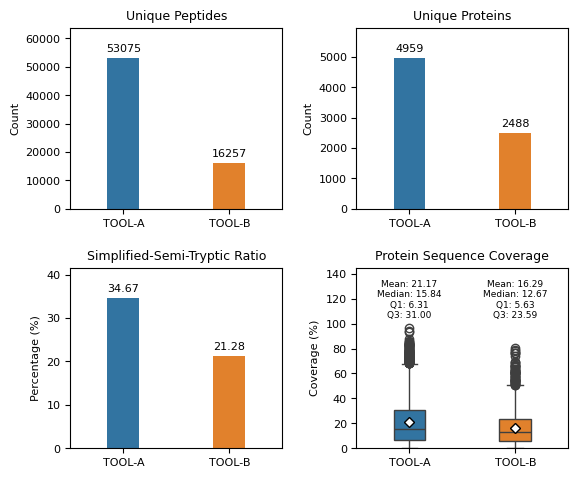

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns

tool_palette = {
    "TOOL-A": "#1f77b4",
    "TOOL-B": "#ff7f0e"
}

fig, axes = plt.subplots(2, 2, figsize=(6, 5))

# Define barplot metrics and number formats
bar_metrics = [
    ("Unique_Peptides", "Unique Peptides", "Count", "%.0f"),
    ("Unique_Proteins", "Unique Proteins", "Count", "%.0f"),
    ("SST_Ratio", "Simplified-Semi-Tryptic Ratio", "Percentage (%)", "%.2f")
]

# Plot the first three metrics
for ax, (metric, title, ylabel, number_format) in zip(axes.flat[:3], bar_metrics):

    sns.barplot(
        data=evaluate_df,
        x="Tool",
        y=metric,
        hue="Tool",
        palette=tool_palette,
        legend=False,
        width=0.3,
        ax=ax
    )

    ax.set_title(title, fontsize=9)
    ax.set_ylabel(ylabel, fontsize=8)
    ax.set_xlabel("")

    # Add extra space above bars
    max_value = evaluate_df[metric].max()
    ax.set_ylim(0, max_value * 1.2 if max_value > 0 else 1)

    # Display values above bars
    for container in ax.containers:
        ax.bar_label(
            container,
            fmt=number_format,
            padding=3,
            fontsize=8
        )

# Plot Protein Coverage boxplot
ax = axes[1, 1]

sns.boxplot(
    data=coverage_comparison,
    x="Tool",
    y="Coverage",
    hue="Tool",
    palette=tool_palette,
    legend=False,
    width=0.3,
    showmeans=True,
    meanprops={
        "marker": "D",
        "markerfacecolor": "white",
        "markeredgecolor": "black",
        "markersize": 5
    },
    ax=ax
)

ax.set_title("Protein Sequence Coverage", fontsize=9)
ax.set_ylabel("Coverage (%)", fontsize=8)
ax.set_xlabel("")

# Add extra space above boxplot
y_min = coverage_comparison["Coverage"].min()
y_max = coverage_comparison["Coverage"].max()
ax.set_ylim(max(0, y_min - (y_max - y_min) * 0.15),
            y_max + (y_max - y_min) * 0.5)

# Annotate boxplot statistics
for i, tool in enumerate(["TOOL-A", "TOOL-B"]):

    values = coverage_comparison.loc[
        coverage_comparison["Tool"] == tool,
        "Coverage"
    ]

    q1 = values.quantile(0.25)
    median = values.median()
    q3 = values.quantile(0.75)
    mean = values.mean()

    stats_text = (
        f"Mean: {mean:.2f}\n"
        f"Median: {median:.2f}\n"
        f"Q1: {q1:.2f}\n"
        f"Q3: {q3:.2f}"
    )

    ax.text(
        i,
        y_max + (y_max - y_min) * 0.4,
        stats_text,
        fontsize=6.5,
        ha="center",
        va="top"
    )

# Adjust all subplots
for ax in axes.flat:
    ax.tick_params(axis="both", labelsize=8)
    ax.set_xlabel("")

plt.tight_layout(pad=1.5)
plt.show()

**6. 결론**

동일한 FASTA file을 TOOL-A와 TOOL-B로 분석하고, Reference Protein Sequence를 활용하여 네 가지 평가 기준에 따라 성능을 비교하였다. 분석 결과, TOOL-A는 모든 평가 기준에서 TOOL-B보다 우수한 결과를 보였다.

TOOL-A는 53,075개의 Unique Peptides와 4,959개의 Unique Proteins를 식별했는데 이는 TOOL-B와 비교했을 때 각각 약 3.27배, 1.99배 높은 수치이다.

Simplified-Semi-Tryptic Ratio의 경우 TOOL-A가 34.67%로 TOOL-B의 21.28%보다 13.39%p 높았다.

Protein Sequence Coverage에서도 TOOL-A의 평균과 중앙값은 각각 21.17%, 15.84%로 TOOL-B의 16.29%, 12.67%보다 높게 나타났다. 이는 TOOL-A가 식별한 Protein에서 상대적으로 더 넓은 아미노산 서열 영역을 포함하는 Peptide를 검출했음을 보여준다.

종합하면 이번 분석에서 TOOL-A는 Unique Peptide 및 Unique Protein 식별 , Simplified-Semi-Tryptic 기준 부합 정도, Protein Sequence Coverage 측면에서 TOOL-B보다 우수한 성능을 보였다. 따라서 주어진 평가 기준 하에서 TOOL-A를 더 나은 성능을 보이는 분석 도구로 판단할 수 있다.